# Lab 8 — Agglomerative Clustering
## Customer Segmentation on the Loan Eligibility Dataset

---

| Detail | Information |
|---|---|
| **Lab No.** | 8 |
| **Module** | 5 — Clustering |
| **Algorithm** | Agglomerative (Hierarchical) Clustering |
| **Dataset** | Loan_Data_Preprocessed.csv (output of the preprocessing notebook) |
| **Goal** | Group loan applicants into segments with similar financial profiles, without using `Loan_Status` |
| **Linkage** | Ward (minimises within-cluster variance) |
| **Number of clusters** | Not fixed in advance — chosen after inspecting the dendrogram (see Section 4) |

---
Memebers:
|  ||
|---|---|
| **Shreedhar Khorate** | 25101B2007 |
| **Bhushan Avhad** | 25101B2006 |


---

## Notebook Contents

| Section | Description |
|---|---|
| 0 | Import libraries |
| 1 | Load the preprocessed dataset |
| 2 | Select clustering features |
| 3 | Build and plot the dendrogram |
| 4 | Choose the number of clusters |
| 5 | Apply Agglomerative Clustering |
| 6 | Visualise the clusters (PCA 2D projection) |
| 7 | Profile the clusters |
| 8 | Compare clusters against Loan_Status |
| 9 | Save the clustered dataset |


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


---
## Section 0 — Import Libraries

- **pandas / numpy**: data handling.
- **matplotlib / seaborn**: visualisation.
- **scipy.cluster.hierarchy**: `linkage` and `dendrogram` for hierarchical clustering.
- **sklearn.cluster.AgglomerativeClustering**: fits the final flat clustering once we pick a cluster count.
- **sklearn.preprocessing.StandardScaler**: re-scales the selected feature subset before computing distances.
- **sklearn.decomposition.PCA**: projects the multi-dimensional feature space down to 2D purely for plotting.

In [ ]:
# -----------------------------------------------------------------------
# Section 0: Import Libraries
# Purpose : Load all libraries needed for hierarchical clustering.
# -----------------------------------------------------------------------

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import AgglomerativeClustering
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Global plot appearance
plt.rcParams['figure.figsize'] = (12, 6)
sns.set_theme(style='whitegrid', palette='muted')

import warnings
warnings.filterwarnings('ignore')

print('All libraries loaded successfully.')

All libraries loaded successfully.


---
## Section 1 — Load the Preprocessed Dataset

We load `Loan_Data_Preprocessed.csv` — the fully cleaned, encoded, and scaled output
of the earlier preprocessing notebook. Since clustering is **unsupervised**, we will
deliberately set `Loan_Status` aside during clustering itself and only bring it back
afterwards (Section 8) to see whether the segments we find line up with real approval
outcomes.

In [ ]:
# -----------------------------------------------------------------------
# Section 1: Load the preprocessed dataset
# Purpose : Read Loan_Data_Preprocessed.csv and confirm it loaded correctly.
#
# NOTE: Update file_path below to match where the file lives in your
#       environment (e.g. a Google Drive path if running in Colab).
# -----------------------------------------------------------------------

 # <-- update path if needed

df = pd.read_csv("/content/drive/MyDrive/Loan/Loan_Data_Preprocessed.csv")

print("Dataset loaded successfully.")
print("Shape:", df.shape)
df.head()

Dataset loaded successfully.
Shape: (529, 22)


,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,...,Log_ApplicantIncome,Log_CoapplicantIncome,Log_LoanAmount,Log_TotalIncome,EMI,LoanToIncome,BalanceIncome,Property_Area_Rural,Property_Area_Semiurban,Property_Area_Urban
0,1,0,0,0,0,0.966197,-0.931152,0.041113,0.264335,1.0,...,1.064349,-1.136980,0.210422,0.413662,-0.121280,-0.344145,0.276025,0,0,1
1,1,1,1,0,0,0.275041,0.156993,0.041113,0.264335,1.0,...,0.489606,0.793137,0.210422,0.524036,-0.121280,-0.452958,0.400510,1,0,0
2,1,1,0,0,1,-0.589178,-0.931152,-1.351903,0.264335,1.0,...,-0.508781,-1.136980,-1.414162,-1.403885,-0.486227,-0.330083,-1.100909,0,0,1
3,1,1,0,1,0,-0.816834,0.770337,-0.138631,0.264335,1.0,...,-0.861370,0.910959,0.051659,-0.045619,-0.168370,-0.043525,-0.179619,0,0,1
4,1,0,0,0,0,1.048634,-0.931152,0.333197,0.264335,1.0,...,1.124410,-1.136980,0.448522,0.483055,-0.044759,-0.141872,0.335124,0,0,1


---
## Section 2 — Select Clustering Features

The preprocessed file has 22 columns, but not all of them are useful for grouping
applicants by *financial profile*, which is the goal of this segmentation:

- We **exclude** `Loan_Status` — it's the target, not a feature to cluster on.
- We **exclude** the raw `ApplicantIncome`, `CoapplicantIncome`, `LoanAmount`, and
  `TotalIncome` columns — their log-transformed counterparts (`Log_...`) already
  capture the same information in a less skewed form, so keeping both would just
  double-count the same signal and distort Euclidean distances.
- We **exclude** the one-hot `Property_Area_*` and demographic columns
  (`Gender`, `Married`, `Dependents`, `Education`, `Self_Employed`) for the main
  clustering — mixing binary/categorical flags with continuous financial ratios in
  a distance-based method tends to let the binary columns dominate or get ignored
  depending on scale, so we keep this first pass purely financial.
- We **keep** the features that describe an applicant's financial standing:
  `Log_ApplicantIncome`, `Log_CoapplicantIncome`, `Log_TotalIncome`, `Log_LoanAmount`,
  `EMI` (estimated monthly instalment), `LoanToIncome` (loan burden relative to income),
  `BalanceIncome` (income left after the EMI), and `Credit_History`.

This mirrors the handout's Mall Customers example (Annual Income + Spending Score),
just with a richer, loan-specific feature set.

In [ ]:
# -----------------------------------------------------------------------
# Section 2: Select features for clustering
# Purpose : Build the feature matrix used to compute distances between
#           applicants. Loan_Status is kept aside separately for Section 8.
# -----------------------------------------------------------------------

cluster_features = [
    'Log_ApplicantIncome',
    'Log_CoapplicantIncome',
    'Log_TotalIncome',
    'Log_LoanAmount',
    'EMI',
    'LoanToIncome',
    'BalanceIncome',
    'Credit_History',
]

X_cluster = df[cluster_features].copy()
loan_status = df['Loan_Status'].copy()   # set aside, not used for clustering

print("Features selected for clustering:")
print(cluster_features)
print("\nShape of clustering matrix:", X_cluster.shape)
X_cluster.describe().T

Features selected for clustering:
['Log_ApplicantIncome', 'Log_CoapplicantIncome', 'Log_TotalIncome', 'Log_LoanAmount', 'EMI', 'LoanToIncome', 'BalanceIncome', 'Credit_History']

Shape of clustering matrix: (529, 8)


,count,mean,std,min,25%,50%,75%,max
Log_ApplicantIncome,529.0,-1.210542e-15,1.000947,-3.096381,-0.698405,-0.078569,0.644791,2.360678
Log_CoapplicantIncome,529.0,-6.380110e-17,1.000947,-1.136980,-1.136980,0.743692,0.888693,1.140162
Log_TotalIncome,529.0,1.935860e-15,1.000947,-3.397674,-0.689694,-0.013304,0.661312,2.740079
Log_LoanAmount,529.0,1.366687e-15,1.000947,-6.131061,-0.396371,0.132311,0.617283,1.957977
EMI,529.0,-3.357952e-17,1.000947,-0.821742,-0.286095,-0.121280,0.067079,18.726439
LoanToIncome,529.0,1.846874e-16,1.000947,-2.609730,-0.557150,-0.019407,0.453092,7.267938
BalanceIncome,529.0,1.108124e-16,1.000947,-3.459262,-0.701906,-0.177561,0.487615,4.335384
Credit_History,529.0,8.525520e-01,0.354888,0.000000,1.000000,1.000000,1.000000,1.000000


### Standardising Only What Isn't Already Scaled

Most of the chosen columns (`Log_ApplicantIncome`, `Log_CoapplicantIncome`,
`Log_TotalIncome`, `Log_LoanAmount`, `EMI`, `LoanToIncome`, `BalanceIncome`) were
already standardised (mean 0, std 1) in the preprocessing notebook — running
`StandardScaler` on them again would be a no-op (and is why re-scaling everything
would just print back `~0.0` means with no real change).

The one exception is `Credit_History`, which is still a raw 0/1 flag. If we left it
unscaled, its tiny numeric range (0 to 1) would barely register against the other
features when computing Euclidean distances. So we scale **only** `Credit_History`
and leave the already-standardised columns untouched.

In [ ]:
# -----------------------------------------------------------------------
# Section 2b: Standardise only the not-yet-scaled column
# Purpose : Credit_History is the only selected feature still on its raw
#           0/1 scale. We standardise it and leave the already-scaled
#           Log_/EMI/ratio columns exactly as they came from preprocessing.
# -----------------------------------------------------------------------

X_scaled = X_cluster.copy()

scaler = StandardScaler()
X_scaled[['Credit_History']] = scaler.fit_transform(X_cluster[['Credit_History']])

print("Feature means after scaling Credit_History (others left as-is):")
print(X_scaled.mean().round(3))

Feature means after scaling Credit_History (others left as-is):
Log_ApplicantIncome     -0.0
Log_CoapplicantIncome   -0.0
Log_TotalIncome          0.0
Log_LoanAmount           0.0
EMI                     -0.0
LoanToIncome             0.0
BalanceIncome            0.0
Credit_History          -0.0
dtype: float64


---
## Section 3 — Build and Plot the Dendrogram

We compute the hierarchical linkage matrix using **Ward's method**, which merges
clusters in the way that minimises the increase in within-cluster variance at each
step — a good default for numerical customer/applicant segmentation.

Because we have 529 applicants, plotting every individual leaf would be unreadable,
so we show two views:

1. A **truncated dendrogram** (`truncate_mode='lastp'`) showing only the last 30
   merges — this is what you actually read to decide where to cut.
2. The **last 10 merge distances**, to see numerically how big the jumps are.

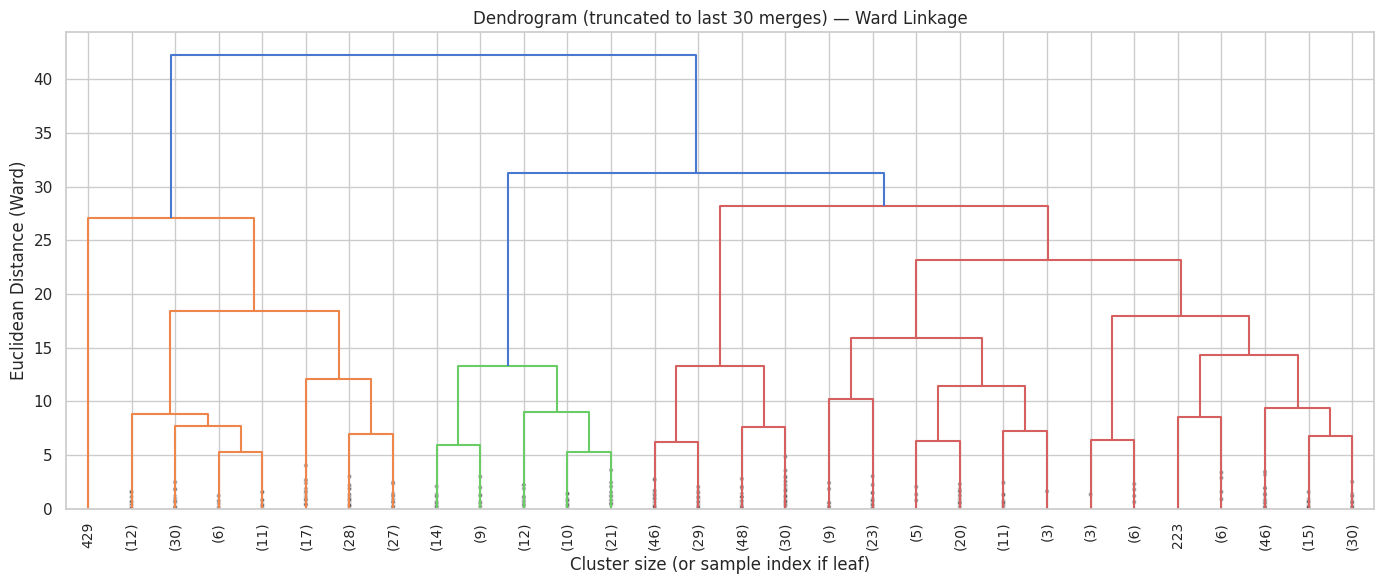

In [ ]:
# -----------------------------------------------------------------------
# Section 3: Compute linkage and plot the dendrogram
# Purpose : Visualise the merge hierarchy so we can decide how many
#           clusters to cut the tree into.
# -----------------------------------------------------------------------

linked = linkage(X_scaled, method='ward')

plt.figure(figsize=(14, 6))
dendrogram(
    linked,
    truncate_mode='lastp',   # show only the last p merged clusters
    p=30,                    # number of leaves to show
    leaf_rotation=90.,
    leaf_font_size=10.,
    show_contracted=True,    # mark contracted branches with a dot
)
plt.title('Dendrogram (truncated to last 30 merges) — Ward Linkage')
plt.xlabel('Cluster size (or sample index if leaf)')
plt.ylabel('Euclidean Distance (Ward)')
plt.axhline(y=0, color='grey', linewidth=0.5)
plt.tight_layout()
plt.show()

---
## Section 4 — Choose the Number of Clusters

**How to read the dendrogram above:** draw an imaginary horizontal line across the
plot. The number of vertical lines it crosses is the number of clusters you'd get by
cutting at that height. A good cut point is usually right *before* a big jump in
merge distance — that jump means the next merge would combine two genuinely
dissimilar groups.

To help you pick a starting point, the cell below prints the **last 10 merge
distances** and highlights the biggest jump between them (a common heuristic).
Treat this as a suggestion, not a rule — look at the dendrogram yourself and set
`N_CLUSTERS` in Section 5 to whatever height makes sense for your data and your
business question (e.g. "3 risk tiers" or "5 marketing segments").

In [ ]:
# -----------------------------------------------------------------------
# Section 4: Data-driven suggestion for number of clusters
# Purpose : Look at the last few merge distances in the linkage matrix and
#           flag where the biggest jump occurs, as a starting heuristic.
# -----------------------------------------------------------------------

last_merges = linked[-10:, 2]          # merge distances, last 10 merges
last_merges_rev = last_merges[::-1]    # reverse: largest merges first

jumps = np.diff(last_merges_rev)
suggested_k = np.argmax(np.abs(jumps)) + 2   # +2 accounts for index offset

print("Last 10 merge distances (largest first):")
for i, d in enumerate(last_merges_rev, start=1):
    print(f"  Merge -{i}: distance = {d:.3f}")

print(f"\nHeuristic suggestion: {suggested_k} clusters "
      f"(biggest jump in merge distance).")
print("Inspect the dendrogram above and confirm this looks right before proceeding.")

Last 10 merge distances (largest first):
  Merge -1: distance = 42.274
  Merge -2: distance = 31.261
  Merge -3: distance = 28.236
  Merge -4: distance = 27.048
  Merge -5: distance = 23.200
  Merge -6: distance = 18.404
  Merge -7: distance = 17.951
  Merge -8: distance = 15.894
  Merge -9: distance = 14.347
  Merge -10: distance = 13.323

Heuristic suggestion: 2 clusters (biggest jump in merge distance).
Inspect the dendrogram above and confirm this looks right before proceeding.


---
## Section 5 — Apply Agglomerative Clustering

Set `N_CLUSTERS` below to the value you decided on after inspecting the dendrogram
and the heuristic suggestion. The default is set to the heuristic value, but you
should change it if the dendrogram tells a different story.

In [ ]:
# -----------------------------------------------------------------------
# Section 5: Fit Agglomerative Clustering with the chosen number of clusters
# Purpose : Produce a flat cluster label for every applicant.
#
#   >>> EDIT N_CLUSTERS below based on your reading of the dendrogram <<<
# -----------------------------------------------------------------------

N_CLUSTERS = suggested_k   # <-- override with your own choice, e.g. N_CLUSTERS = 4

agg_model = AgglomerativeClustering(n_clusters=N_CLUSTERS, linkage='ward')
df['Cluster'] = agg_model.fit_predict(X_scaled)

print(f"Applied Agglomerative Clustering with {N_CLUSTERS} clusters.")
print("\nCluster sizes:")
print(df['Cluster'].value_counts().sort_index())

Applied Agglomerative Clustering with 2 clusters.

Cluster sizes:
Cluster
0    397
1    132
Name: count, dtype: int64


---
## Section 6 — Visualise the Clusters (PCA 2D Projection)

The clustering used 8 features, which we can't plot directly. To visualise the
result, we project the scaled feature space down to 2 principal components with
PCA and colour each point by its assigned cluster. This is purely for visual
inspection — the actual clustering was done in the full 8-dimensional space.

Variance explained by PC1: 39.1%
Variance explained by PC2: 18.6%
Total variance captured in 2D: 57.6%


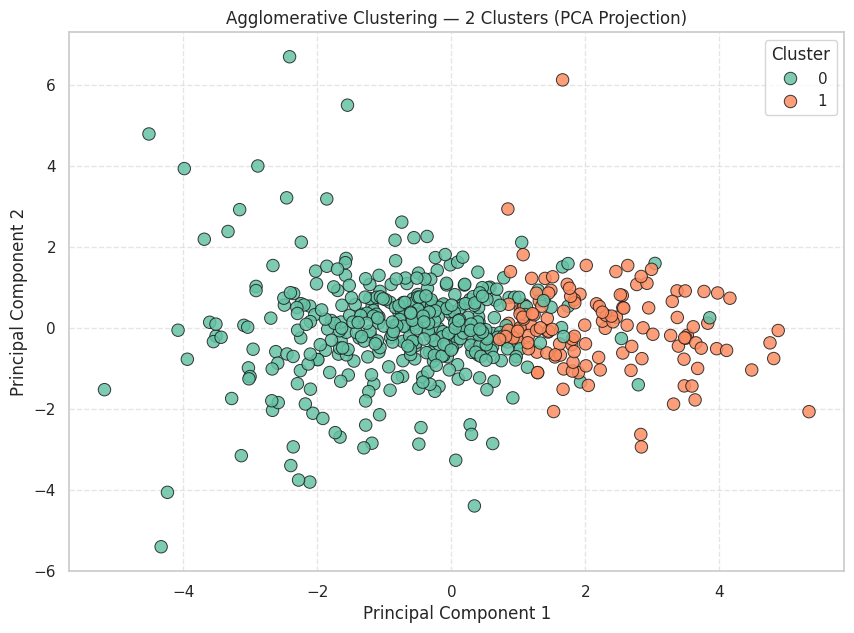

In [ ]:
# -----------------------------------------------------------------------
# Section 6: PCA projection for visualisation
# Purpose : Reduce the 8 clustering features to 2 components so the
#           cluster structure can be plotted on a scatter plot.
# -----------------------------------------------------------------------

pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

explained = pca.explained_variance_ratio_
print(f"Variance explained by PC1: {explained[0]*100:.1f}%")
print(f"Variance explained by PC2: {explained[1]*100:.1f}%")
print(f"Total variance captured in 2D: {sum(explained)*100:.1f}%")

plt.figure(figsize=(10, 7))
sns.scatterplot(
    x=X_pca[:, 0], y=X_pca[:, 1],
    hue=df['Cluster'], palette='Set2',
    s=80, alpha=0.85, edgecolor='k'
)
plt.title(f'Agglomerative Clustering — {N_CLUSTERS} Clusters (PCA Projection)')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend(title='Cluster')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

---
## Section 7 — Profile the Clusters

Numbers on a scatter plot don't tell a loan officer much on their own. Here we look
at the **average value of each original financial feature per cluster** (on the raw,
un-scaled scale where possible) so each segment can be described in plain terms,
e.g. "high income, low loan burden" vs. "low income, high EMI relative to income".

In [ ]:
# -----------------------------------------------------------------------
# Section 7: Cluster profiling
# Purpose : Summarise each cluster's average characteristics to give each
#           segment a human-readable description.
# -----------------------------------------------------------------------

profile_cols = cluster_features + ['Dependents', 'Married', 'Education',
                                    'Self_Employed', 'Property_Area_Urban',
                                    'Property_Area_Semiurban', 'Property_Area_Rural']

cluster_profile = df.groupby('Cluster')[profile_cols].mean().round(2)
print("Average feature values per cluster:")
cluster_profile

Average feature values per cluster:


,Log_ApplicantIncome,Log_CoapplicantIncome,Log_TotalIncome,Log_LoanAmount,EMI,LoanToIncome,BalanceIncome,Credit_History,Dependents,Married,Education,Self_Employed,Property_Area_Urban,Property_Area_Semiurban,Property_Area_Rural
Cluster,,,,,,,,,,,,,,,
0,-0.37,-0.00,-0.39,-0.27,-0.11,0.11,-0.4,0.8,0.68,0.63,0.28,0.09,0.34,0.38,0.28
1,1.13,0.01,1.16,0.80,0.33,-0.34,1.2,1.0,0.84,0.71,0.14,0.20,0.26,0.41,0.33


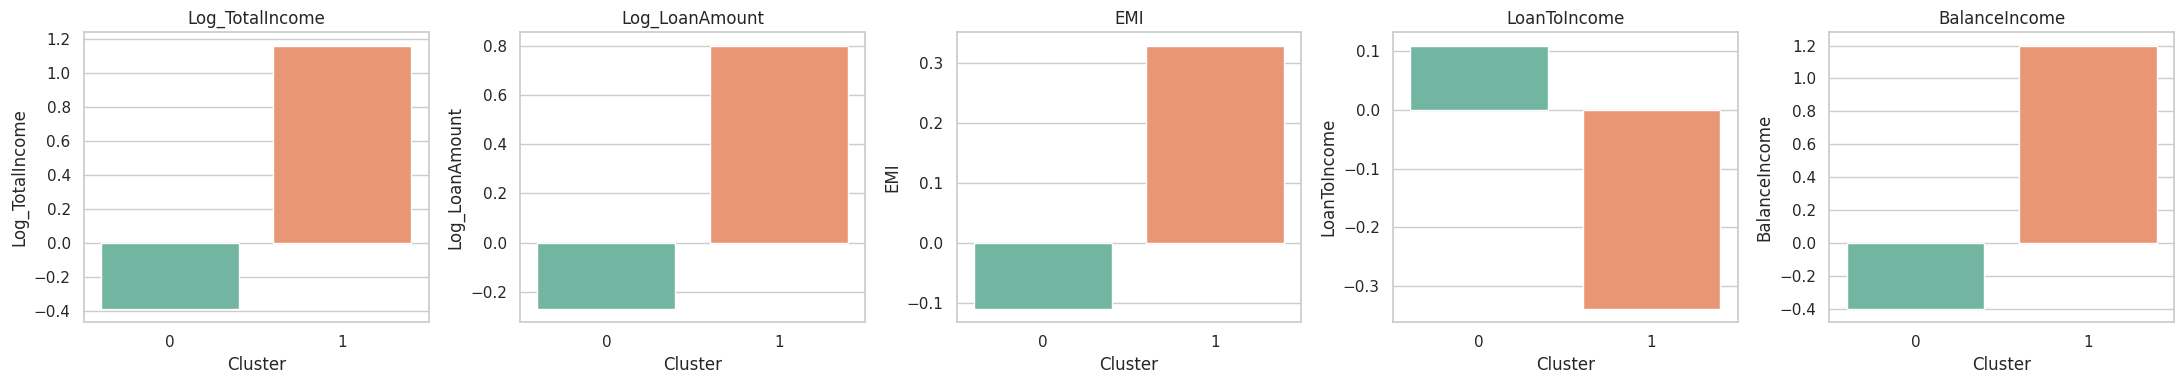

In [ ]:
# -----------------------------------------------------------------------
# Section 7b: Visualise key financial differences between clusters
# Purpose : Bar charts of the core financial features by cluster, to make
#           the segment differences easy to see at a glance.
# -----------------------------------------------------------------------

key_features = ['Log_TotalIncome', 'Log_LoanAmount', 'EMI', 'LoanToIncome', 'BalanceIncome']

fig, axes = plt.subplots(1, len(key_features), figsize=(22, 4))
for ax, feature in zip(axes, key_features):
    sns.barplot(x=cluster_profile.index, y=cluster_profile[feature], ax=ax, palette='Set2')
    ax.set_title(feature)
    ax.set_xlabel('Cluster')

plt.tight_layout()
plt.show()

---
## Section 8 — Compare Clusters Against Loan_Status

The clustering never saw `Loan_Status` — it grouped applicants purely by financial
profile. Now we bring the target back in to check whether the segments we found
naturally differ in their real-world approval rate. This is a sanity check, not a
classification result: clustering and classification are solving different problems,
but it's informative to see if the unsupervised groups mean anything in terms of
actual outcomes.

Loan approval rate by cluster:
         Rejected %  Approved %
Cluster                        
0              33.5        66.5
1              22.0        78.0


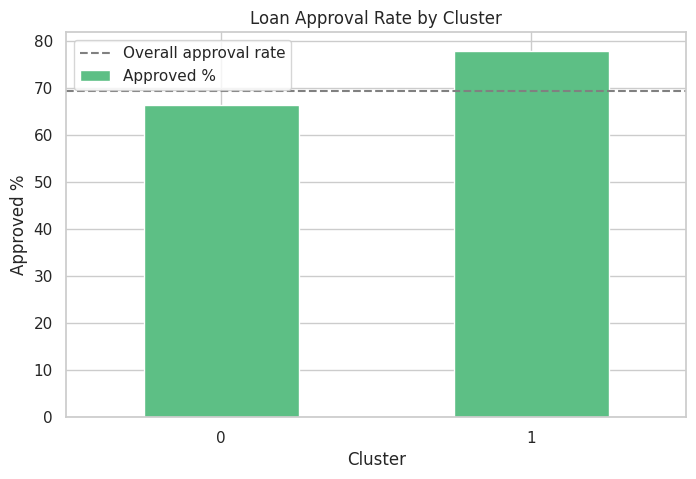

In [ ]:
# -----------------------------------------------------------------------
# Section 8: Loan_Status distribution per cluster
# Purpose : Check the approval rate within each cluster to see whether the
#           unsupervised segments align with real loan outcomes.
# -----------------------------------------------------------------------

status_by_cluster = pd.crosstab(df['Cluster'], df['Loan_Status'], normalize='index') * 100
status_by_cluster.columns = ['Rejected %', 'Approved %']
print("Loan approval rate by cluster:")
print(status_by_cluster.round(1))

status_by_cluster['Approved %'].plot(kind='bar', color='#5dbf85', figsize=(8, 5))
plt.title('Loan Approval Rate by Cluster')
plt.xlabel('Cluster')
plt.ylabel('Approved %')
plt.axhline(y=df['Loan_Status'].mean() * 100, color='grey', linestyle='--',
            label='Overall approval rate')
plt.legend()
plt.xticks(rotation=0)
plt.show()

---
## Section 9 — Save the Clustered Dataset

Finally, we export the dataset with the new `Cluster` column attached, so the
segments can be reused in a dashboard, a follow-up model, or a marketing/risk
workflow.

In [ ]:
# -----------------------------------------------------------------------
# Section 9: Save output
# Purpose : Export the dataset with cluster labels attached.
# -----------------------------------------------------------------------

output_path = "Loan_Data_Clustered.csv"
df.to_csv(output_path, index=False)

print(f"Saved clustered dataset to '{output_path}'.")
print("Shape:", df.shape)
df.head()

Saved clustered dataset to 'Loan_Data_Clustered.csv'.
Shape: (529, 23)


,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,...,Log_CoapplicantIncome,Log_LoanAmount,Log_TotalIncome,EMI,LoanToIncome,BalanceIncome,Property_Area_Rural,Property_Area_Semiurban,Property_Area_Urban,Cluster
0,1,0,0,0,0,0.966197,-0.931152,0.041113,0.264335,1.0,...,-1.136980,0.210422,0.413662,-0.121280,-0.344145,0.276025,0,0,1,1
1,1,1,1,0,0,0.275041,0.156993,0.041113,0.264335,1.0,...,0.793137,0.210422,0.524036,-0.121280,-0.452958,0.400510,1,0,0,0
2,1,1,0,0,1,-0.589178,-0.931152,-1.351903,0.264335,1.0,...,-1.136980,-1.414162,-1.403885,-0.486227,-0.330083,-1.100909,0,0,1,0
3,1,1,0,1,0,-0.816834,0.770337,-0.138631,0.264335,1.0,...,0.910959,0.051659,-0.045619,-0.168370,-0.043525,-0.179619,0,0,1,0
4,1,0,0,0,0,1.048634,-0.931152,0.333197,0.264335,1.0,...,-1.136980,0.448522,0.483055,-0.044759,-0.141872,0.335124,0,0,1,1


In [19]:
# Analyze the Clusters

# Average value of each clustering feature per cluster
cluster_summary = df.groupby('Cluster')[cluster_features].mean().round(2)
print("Average feature values per cluster:")
print(cluster_summary)

# Number of applicants in each cluster
print("\nCluster sizes:")
print(df['Cluster'].value_counts().sort_index())

Average feature values per cluster:
         Log_ApplicantIncome  Log_CoapplicantIncome  Log_TotalIncome  \
Cluster                                                                
0                      -0.37                  -0.00            -0.39   
1                       1.13                   0.01             1.16   

         Log_LoanAmount   EMI  LoanToIncome  BalanceIncome  Credit_History  
Cluster                                                                     
0                 -0.27 -0.11          0.11           -0.4             0.8  
1                  0.80  0.33         -0.34            1.2             1.0  

Cluster sizes:
Cluster
0    397
1    132
Name: count, dtype: int64


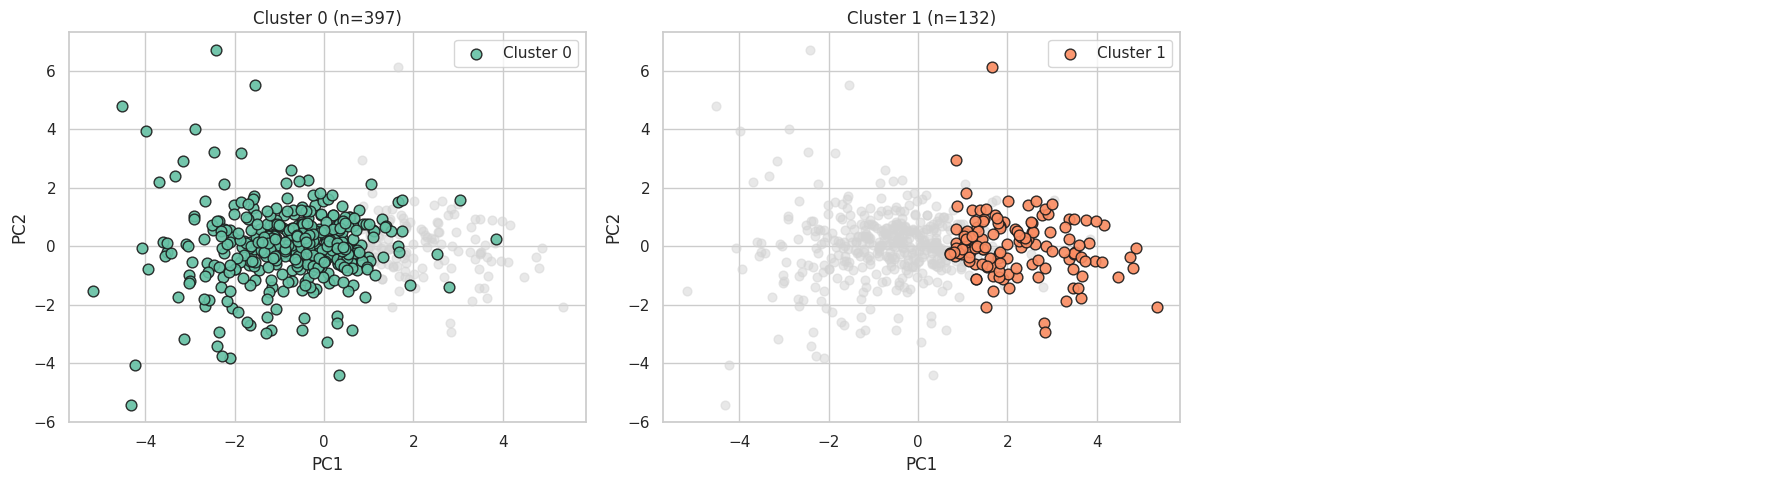

In [20]:
# Visualize each cluster separately (PCA 2D projection)

n = N_CLUSTERS
cols = 3
rows = -(-n // cols)  # ceil division

fig, axes = plt.subplots(rows, cols, figsize=(6*cols, 5*rows))
axes = axes.flatten() if n > 1 else [axes]

for cluster_id in range(n):
    ax = axes[cluster_id]

    # Plot all points in light grey as context
    ax.scatter(X_pca[:, 0], X_pca[:, 1], color='lightgrey', s=40, alpha=0.5)

    # Highlight only this cluster's points
    mask = df['Cluster'] == cluster_id
    ax.scatter(X_pca[mask, 0], X_pca[mask, 1], color=sns.color_palette('Set2')[cluster_id],
               s=60, edgecolor='k', alpha=0.9, label=f'Cluster {cluster_id}')

    ax.set_title(f'Cluster {cluster_id} (n={mask.sum()})')
    ax.set_xlabel('PC1')
    ax.set_ylabel('PC2')
    ax.legend()

# Hide any unused subplots
for j in range(n, len(axes)):
    axes[j].axis('off')

plt.tight_layout()
plt.show()